## 📌 PCA (Principal Component Analysis) Nədir və Niyə Vacibdir?

**PCA (Əsas Komponentlərin Təhlili)** — maşın öyrənməsində ən çox istifadə olunan **ölçülərin azaldılması (dimensionality reduction)** texnikasıdır. 

Onun əsas məqsədi: çoxlu sayda sütuna/ölçüyə malik olan mürəkkəb verilənlər bazasını, **məlumatdakı ümumi müxtəlifliyi (dispersiyanı / variance)** maksimum dərəcədə qoruyub saxlamaq şərtilə daha az sayda (məsələn, 2 və ya 3) yeni əsas oxa (komponentə) sıxmaqdır.

---

### 💡 Həyatdan Sadə Analogiyalar:
1. **Kölgə Analogiyası:** 3D bir cismin (məsələn, əlinizin) divara düşən kölgəsi 2D-dir. Əgər əlinizi işığa düzgün bucaq altında tutsanız, 2D kölgədən onun 5 barmaqlı əl olduğunu asanlıqla anlaya bilərsiniz. PCA məhz verilənlərin ən aydın və ən informativ "kölgəsini" tapan alətdir.
2. **Ağ-Qara Təsvirlər və Üz Tanıma (Facial Recognition):** Ağ-qara şəkildə hər bir nöqtə 3 ölçü ilə xarakterizə olunur: X koordinatı, Y koordinatı və parlaqlıq dərəcəsi. Bunu 2 ölçüyə sıxmaq təsvirlərin sıxılmasında (compression) və məlumatın ən informativ xüsusiyyətlərini seçməkdə çox faydalıdır.

---

### 🌸 İris Verilənlər Bazası (Iris Dataset):
Bu dərsimizdə `scikit-learn` kitabxanasının məşhur **Iris** məlumat bazasından istifadə edəcəyik. Bu baza 3 fərqli növə aid İris (Süsən) çiçəklərinin 4 fərqli həndəsi ölçüsünü ehtiva edir:
- **Sepal Length:** Kasa yarpağının uzunluğu
- **Sepal Width:** Kasa yarpağının eni
- **Petal Length:** Ləçəyin uzunluğu
- **Petal Width:** Ləçəyin eni

In [ ]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from itertools import cycle
import pylab as pl
%matplotlib inline

iris = load_iris()
iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [ ]:
numSamples, numFeatures = iris.data.shape

print(f"Nümunələrin sayı (Samples): {numSamples}")
print(f"Əlamətlərin sayı (Features): {numFeatures}")
print(f"Çiçək növləri (Target Classes): {list(iris.target_names)}")


Nümunələrin sayı (Samples): 150
Əlamətlərin sayı (Features): 4
Çiçək növləri (Target Classes): ['setosa', 'versicolor', 'virginica']


## 🔍 Məlumatın Quruluşunun Təhlili

Yuxarıdakı çıxış bizə göstərir ki:
- **150 nümunə (samples):** Bazada cəmi 150 ədəd fərdi çiçək ölçülmüşdür.
- **4 əlamət (features / ölçü):** Hər çiçək üçün 4 parametr (ləçək və kasa yarpağının eni və uzunluğu) qeyd edilmişdir.
- **3 fərqli sinif (species):** Hər bir çiçək 3 növdən birinə aiddir: `'setosa'`, `'versicolor'` və `'virginica'` (hər birindən 50 ədəd).

> 🧠 **İnsan Beyni və Çoxölçülü Fəza Məhdudiyyəti:**  
> Biz 2 ölçülü (müstəvi) və ya 3 ölçülü (həcmli) qrafikləri asanlıqla gözümüz önündə canlandıra bilirik. Lakin **4 ölçülü (4D)** bir fəzanı kompüter ekranında vizuallaşdırmaq və ya insan beynində təsəvvür etmək qeyri-mümkündür!  
> Məhz buna görə də biz bu **4 ölçülü veriləni ən informativ 2 ölçüyə (2D)** endirəcəyik ki, həm təhlil edə, həm də sadə müstəvidə vizual qrafikini qura bilək.

In [10]:
# Giriş əlamətləri matrisi (X) - 150 sətir və 4 sütundan ibarətdir
X = iris.data
X


array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [11]:
# PCA modelinin yaradılması və məlumatlara uyğunlaşdırılması (fit edilməsi)
# n_components=2 -> 4 ölçüdən 2 əsas komponentə (ölçüyə) endiririk
# whiten=True -> 'Ağartma' (komponentlərin dispersiyasını 1-ə gətirərək fərqli miqyasları balanslaşdırır)
pca = PCA(n_components=2, whiten=True).fit(X)
pca


,n_components,2
,copy,True
,whiten,True
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [12]:
# Orijinal 4D məlumatları tapılmış 2 əsas komponentə proyeksiyalayıb (çevirib) X_pca alırıq
X_pca = pca.transform(X)
X_pca


array([[-1.30533786,  0.64836932],
       [-1.31993521, -0.35930856],
       [-1.40496732, -0.29424412],
       [-1.33510889, -0.64613986],
       [-1.32702321,  0.6633044 ],
       [-1.10922246,  1.50488434],
       [-1.3716775 , -0.18160462],
       [-1.27714084,  0.33166784],
       [-1.40369908, -1.17396001],
       [-1.29980851, -0.23095919],
       [-1.2191728 ,  1.30947554],
       [-1.27062918,  0.02990145],
       [-1.35493432, -0.47727214],
       [-1.5677929 , -1.03811965],
       [-1.28618899,  2.39286603],
       [-1.16037307,  2.71623681],
       [-1.2758681 ,  1.64566141],
       [-1.28791362,  0.63304684],
       [-1.06981161,  1.77184386],
       [-1.25858365,  1.04251602],
       [-1.12351854,  0.79442356],
       [-1.23704894,  0.87897239],
       [-1.56396833,  0.27093722],
       [-1.11985996,  0.20037678],
       [-1.14564495, -0.07568135],
       [-1.21903752, -0.29641102],
       [-1.20063096,  0.26582861],
       [-1.24610158,  0.74646111],
       [-1.28365251,

## 🔄 4D-dən 2D-yə Proyeksiyalara Baxış: Ortoqonal Oxlar (Eigenvectors)

Bayaq etdiyimiz əməliyyatla biz nə etdik?
Biz 4 ölçülü verilənlər bazasını iki **ortoqonal (bir-birinə perpendikulyar olan) 4D vektora** proyeksiya edərək yeni bir 2D müstəvi əldə etdik.

Həmin vektorlar (xətti cəbrdə bunlara **məxsusi vektorlar / eigenvectors** deyilir) 4 ölçülü fəzada məlumatın ən çox dəyişdiyi (maksimum dispersiyaya malik) istiqamətləri göstərir. Gəlin bu komponentlərin çəkilərinə baxaq:

In [13]:
# Hər iki əsas komponentin orijinal 4 xüsusiyyət üzrə çəki əmsalları (Eigenvectors)
print("Əsas Komponentlərin Vektorları (Components):")
print(pca.components_)


Əsas Komponentlərin Vektorları (Components):
[[ 0.36138659 -0.08452251  0.85667061  0.3582892 ]
 [ 0.65658877  0.73016143 -0.17337266 -0.07548102]]


## 📊 İzah Olunan Dispersiya Nisbəti (Explained Variance Ratio)

İndi isə ən mühüm suala cavab verək: **Ölçüləri 4-dən 2-yə endirəndə nə qədər informasiya itirdik və nə qədərini qoruya bildik?**

`pca.explained_variance_ratio_` parametri hər bir əsas komponentin ümumi məlumat müxtəlifliyinin (dispersiyasının) neçə faizini özündə saxladığını göstərir:

In [14]:
# Hər bir komponentin izah etdiyi dispersiya payı
print("Hər komponentin izah etdiyi dispersiya nisbəti:")
print(pca.explained_variance_ratio_)

print("\nİki komponentin birlikdə qoruduğu ümumi informasiya (dispersiya):")
print(sum(pca.explained_variance_ratio_))


Hər komponentin izah etdiyi dispersiya nisbəti:
[0.92461872 0.05306648]

İki komponentin birlikdə qoruduğu ümumi informasiya (dispersiya):
0.9776852063187964


## 🎯 Nəticənin Dərin Təhlili: Məlumat İtkisi Cəmi ~2.2%!

Bu nəticə həqiqətən heyrətamizdir:
1. **1-ci Əsas Komponent (1st Component):** Məlumatdakı bütün dəyişkənliyin və fərqliliyin təkbaşına **~92.46%-ni** izah edir!
2. **2-ci Əsas Komponent (2nd Component):** Əlavə olaraq **~5.30%-lik** dispersiyanı əhatə edir.
3. **Cəmi İnformasiya:** İki komponent birlikdə məlumatın **~97.77%-ni** tamamilə qoruyub saxlayır!

> 💎 **Möhtəşəm Üstünlük:**  
> Biz 4 ölçüdən 2-sini kənara atdıq (yəni ölçülərin 50%-ni ixtisar etdik), lakin məlumatın cəmi **2.23%-ni** itirdik! Məlumatın demək olar ki, bütün mahiyyəti bu 2 yeni oxda cəmləndi.

İndi isə söz verdiyimiz kimi, əlimizdə 2D verilənlər olduğuna görə, çiçəklərin fəzada necə paylandığını **sadə 2D qrafikdə vizuallaşdıraq**:

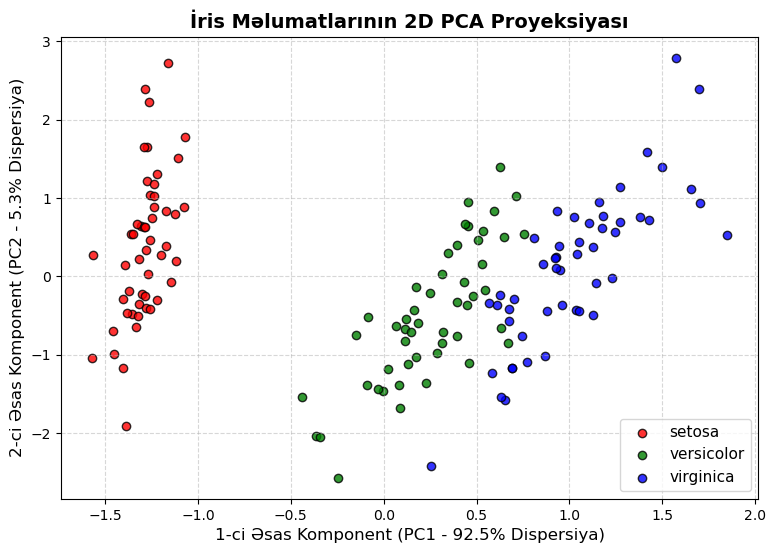

In [15]:
# 2D Proyeksiyanın vizuallaşdırılması (Scatter Plot)
colors = cycle('rgb')
target_ids = range(len(iris.target_names))

pl.figure(figsize=(9, 6))

for i, c, label in zip(target_ids, colors, iris.target_names):
    pl.scatter(X_pca[iris.target == i, 0], X_pca[iris.target == i, 1],
        c=c, label=label, alpha=0.8, edgecolors='k')
    
pl.title('İris Məlumatlarının 2D PCA Proyeksiyası', fontsize=14, fontweight='bold')
pl.xlabel('1-ci Əsas Komponent (PC1 - 92.5% Dispersiya)', fontsize=12)
pl.ylabel('2-ci Əsas Komponent (PC2 - 5.3% Dispersiya)', fontsize=12)
pl.legend(loc='best', fontsize=11)
pl.grid(True, linestyle='--', alpha=0.5)
pl.show()


## 🌸 Qrafikin Bioloji və Həndəsi Şərhi

Qrafikdən aydın görünür ki, 3 fərqli İris növü 2D müstəvidə çox səliqəli şəkildə **klasterləşmişdir (qruplaşmışdır)**:

1. **`setosa` (Qırmızı nöqtələr):** Digər iki növdən tamamilə təcrid olunmuş şəkildə ayrılır. Yəni xətti olaraq çox rahatlıqla digərlərindən fərqləndirilə bilir.
2. **`versicolor` (Yaşıl nöqtələr) və `virginica` (Göy nöqtələr):** Bir-birinə çox yaxındır və kəsişmə zonasında cüzi örtüşmə (overlap) var. Çünki təbiətdə bu iki növün çiçək ölçüləri bir-birinə olduqca bənzərdir.

---

### 🤔 Niyə PCA bu qədər yaxşı işlədi?
Əgər məntiqi düşünsək, bir çiçək böyük olduqda həm onun ləçəkləri, həm də kasa yarpaqları adətən proporsional şəkildə böyüyür. Yəni bu 4 əlamət bir-biri ilə **yüksək korrelyasiyadadır (correlation)**.

- **1-ci Əsas Komponent (PC1):** Çiçəyin **ümumi ölçüsünü** (həm ləçək, həm də kasa yarpağının birgə böyüklüyünü) ifadə edir. Məhz buna görə təkcə bu ox məlumatın 92.5%-ni izah edir!
- **2-ci Əsas Komponent (PC2):** Çiçək hissələrinin **en/uzunluq nisbətini (aspect ratio)** və xırda forma fərqlərini təmsil edir.

---

### 🎓 Yekun Nəticə və Təcrübi Əhəmiyyət:
- **Vizuallaşdırma:** 4D-də kor olduğumuz halda, 2D-də çiçək siniflərinin necə ayrıldığını aydın gördük.
- **Maşın Öyrənməsi Sürətləndirməsi:** Gələcəkdə klassifikasiya modelləri qurarkən 4 xüsusiyyət əvəzinə bu 2 əsas komponentdən istifadə etsək, model daha sürətli işləyəcək və həddindən artıq uyğunlaşmanın (overfitting) qarşısı alınacaq.
- **Autoencoderlərlə Əlaqəsi:** PCA xətti ölçü azaltma metodudur. Dərin öyrənmədə öyrəndiyimiz *Autoencoder* şəbəkələri isə PCA-nın qeyri-xətti, daha mürəkkəb neyron şəbəkə analoqudur!